# PlantSeg Stage 3 — Severity Quantification & Validation (all 6 models, checkpoint-only)

**Updated design:** all 6 models load from `.pt` checkpoint files — no in-notebook retraining.
After running Stage 4 (which trains `DeepLabV3Plus_efficientnet-b3` and `UNet_resnet34` and
saves their weights), upload all 6 `.pt` files as one Kaggle dataset and point `CKPT_ROOT`
to it. Runtime is then ~15 minutes (pure inference + stats), not ~4 hours.

### Required Kaggle inputs
- **PlantSeg dataset** (`Metadata.csv`, `images/`, `annotation_*.json`).
- **A dataset containing all 6 `.pt` checkpoints:**
  - `UNetPP_resnet50.pt`, `DeepLabV3Plus_resnet50.pt`, `FPN_resnet50.pt`, `SegFormer_b2.pt`
    (same dataset used previously)
  - `DeepLabV3Plus_efficientnet-b3.pt`, `UNet_resnet34.pt`
    (downloaded from `WEIGHTS/` after Stage 4 completes)

### Expected runtime
~15 minutes total (no training — inference over 1,561 test images × 6 models + stats).
GPU optional (CPU works, just slower inference).


**Setup** — installs, imports, seeds:

In [1]:
!pip install -q segmentation-models-pytorch albumentations
import os, json, glob, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageDraw
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from transformers import SegformerForSemanticSegmentation
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, cohen_kappa_score
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; torch.manual_seed(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.2 MB/s eta 0:00:00
Device: cuda


**Config** — set `CKPT_ROOT` to the dataset folder that contains all 6 `.pt` files:

In [2]:
# ============ CONFIG ============
DATA_ROOT = Path("/kaggle/input/datasets/marufbangabashi/plantseg/plantseg")
if not (DATA_ROOT/"Metadata.csv").exists():
    for c in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (c/"Metadata.csv").exists(): DATA_ROOT = c; break
    else:
        cand = glob.glob("/kaggle/input/**/Metadata.csv", recursive=True)
        if cand: DATA_ROOT = Path(cand[0]).parent
assert (DATA_ROOT/"Metadata.csv").exists(), f"Metadata.csv not found under {DATA_ROOT}"

# Auto-detect checkpoint folder: find the directory that contains ALL 6 .pt files.
# If your 6 checkpoints are spread across two datasets, set CKPT_ROOT manually below.
_required = {"UNetPP_resnet50.pt","DeepLabV3Plus_resnet50.pt","FPN_resnet50.pt",
             "SegFormer_b2.pt","DeepLabV3Plus_efficientnet-b3.pt","UNet_resnet34.pt"}
CKPT_ROOT = None
for _d in glob.glob("/kaggle/input/*"):
    if all((Path(_d)/f).exists() for f in _required):
        CKPT_ROOT = Path(_d); break
if CKPT_ROOT is None:
    # Fallback: search recursively for any one of them and use its parent
    _cand = glob.glob("/kaggle/input/**/UNetPP_resnet50.pt", recursive=True)
    if _cand: CKPT_ROOT = Path(_cand[0]).parent
assert CKPT_ROOT is not None, (
    "Could not find a folder containing all 6 .pt files under /kaggle/input. "
    "Attach the checkpoint dataset or set CKPT_ROOT manually.")

CHECKPOINTS = {
    "DeepLabV3Plus_efficientnet-b3": CKPT_ROOT/"DeepLabV3Plus_efficientnet-b3.pt",
    "UNet_resnet34":                  CKPT_ROOT/"UNet_resnet34.pt",
    "UNetPP_resnet50":                CKPT_ROOT/"UNetPP_resnet50.pt",
    "DeepLabV3Plus_resnet50":         CKPT_ROOT/"DeepLabV3Plus_resnet50.pt",
    "FPN_resnet50":                   CKPT_ROOT/"FPN_resnet50.pt",
    "SegFormer_b2":                   CKPT_ROOT/"SegFormer_b2.pt",
}
IMG_SIZE = 512
print("DATA_ROOT:", DATA_ROOT)
print("CKPT_ROOT:", CKPT_ROOT)
for name, path in CHECKPOINTS.items():
    print(f"  {name}: {'OK' if path.exists() else 'MISSING'} — {path}")


DATA_ROOT: /kaggle/input/datasets/marufbangabashi/plantseg/plantseg
CKPT_ROOT: /kaggle/input/datasets/marufbangabashi/checkpoints-6-models
  DeepLabV3Plus_efficientnet-b3: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/DeepLabV3Plus_efficientnet-b3.pt
  UNet_resnet34: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/UNet_resnet34.pt
  UNetPP_resnet50: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/UNetPP_resnet50.pt
  DeepLabV3Plus_resnet50: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/DeepLabV3Plus_resnet50.pt
  FPN_resnet50: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/FPN_resnet50.pt
  SegFormer_b2: OK — /kaggle/input/datasets/marufbangabashi/checkpoints-6-models/SegFormer_b2.pt


**Index + binary masks** — reads `Metadata.csv`, rasterises COCO polygon annotations:

In [3]:
MASK = Path("/kaggle/working/masks")
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta.columns = [c.strip() for c in meta.columns]
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
def load_anns(split):
    d = json.load(open(DATA_ROOT/f"annotation_{split}.json")); by = defaultdict(list)
    for a in d["annotations"]: by[a["image_id"]].append(a)
    fn = {}
    for im in d["images"]:
        polys = [seg for a in by.get(im["id"],[]) for seg in a["segmentation"] if len(seg)>=6]
        fn[im["file_name"]] = (im["width"], im["height"], polys)
    return fn
def rasterize(w, h, polys):
    m = Image.new("L",(w,h),0); dr = ImageDraw.Draw(m)
    for seg in polys: dr.polygon(list(zip(seg[0::2],seg[1::2])), fill=1)
    return m
recs = []
for split in ["train","val","test"]:
    fn = load_anns(split); od = MASK/split; od.mkdir(parents=True, exist_ok=True)
    for r in meta[meta.split==split].itertuples():
        w,h,polys = fn.get(r.Name,(None,None,[])); mp = od/(Path(r.Name).stem+".png")
        if not mp.exists():
            if w is None:
                with Image.open(r.filepath) as i0: w,h = i0.size
            rasterize(w,h,polys).save(mp)
        recs.append({"name":r.Name,"filepath":str(r.filepath),"mask":str(mp),
                     "split":split,"disease":r.Disease,"host":r.Plant})
df = pd.DataFrame(recs)
test_df = df[df.split=="test"].reset_index(drop=True)
print(f"Test set: {len(test_df)} images")

gt_by_name = meta.set_index("Name")["Mask ratio"]
print(f"gt_by_name: {len(gt_by_name)} entries, range [{gt_by_name.min():.4f}, {gt_by_name.max():.4f}]")


Test set: 1561 images
gt_by_name: 7774 entries, range [0.0000, 1.0000]


**Transforms / Dataset** — eval pipeline only (no training augmentations needed):

In [4]:
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
eval_tf = A.Compose([A.Resize(IMG_SIZE,IMG_SIZE), A.Normalize(MEAN,STD), ToTensorV2()])
class SegDS(Dataset):
    def __init__(s, d, t): s.df=d.reset_index(drop=True); s.t=t
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r=s.df.iloc[i]; img=np.array(Image.open(r.filepath).convert("RGB")); m=np.array(Image.open(r["mask"]))
        a=s.t(image=img, mask=m); return a["image"], a["mask"].long(), r["name"]
test_loader = DataLoader(SegDS(test_df,eval_tf), batch_size=8, shuffle=False, num_workers=2, pin_memory=True)


**Model + checkpoint helpers** — `SegNet` wrapper, `infer_num_classes`, `per_image_metrics`:

In [5]:
SMP_SPECS = {
    "UNet_resnet34":                (smp.Unet,          "resnet34"),
    "UNetPP_resnet50":              (smp.UnetPlusPlus,  "resnet50"),
    "DeepLabV3Plus_resnet50":       (smp.DeepLabV3Plus, "resnet50"),
    "DeepLabV3Plus_efficientnet-b3":(smp.DeepLabV3Plus, "efficientnet-b3"),
    "FPN_resnet50":                 (smp.FPN,           "resnet50"),
}
SEGFORMER_HF = {"SegFormer_b2":"nvidia/mit-b2"}

class SegNet(nn.Module):
    def __init__(s, name, nc):
        super().__init__()
        if name in SMP_SPECS:
            arch,enc = SMP_SPECS[name]
            s.net = arch(encoder_name=enc, encoder_weights=None, in_channels=3, classes=nc)
            s.kind = "smp"
        else:
            s.net = SegformerForSemanticSegmentation.from_pretrained(
                SEGFORMER_HF[name], num_labels=nc, ignore_mismatched_sizes=True)
            s.kind = "hf"
    def forward(s, x):
        if s.kind=="smp": return s.net(x)
        lg = s.net(pixel_values=x).logits
        return F.interpolate(lg, size=x.shape[-2:], mode="bilinear", align_corners=False)

def infer_num_classes(ckpt_path):
    state = torch.load(ckpt_path, map_location="cpu")
    for k,v in state.items():
        if k.endswith("segmentation_head.0.weight"): return v.shape[0]
    for k,v in state.items():
        if k.endswith("classifier.weight") and v.dim()==4: return v.shape[0]
    raise RuntimeError(f"Cannot infer num_classes from {ckpt_path}")

def per_image_metrics(model, loader):
    """Single pass: returns (fg_iou_arr, pred_ratio_arr, image_names)."""
    model.eval(); fg_list=[]; pr_list=[]; names=[]
    with torch.no_grad():
        for x,y,nm in loader:
            x = x.to(device); preds = model(x).argmax(1).cpu().numpy()
            gt = y.numpy()
            for i in range(len(nm)):
                pred_bin = (preds[i]>0); gt_bin = (gt[i]>0)
                inter=(pred_bin & gt_bin).sum(); union=(pred_bin | gt_bin).sum()
                fg_list.append(float(inter/union) if union>0 else 0.0)
                pr_list.append(float(pred_bin.sum()/pred_bin.size))
                names.append(nm[i])
    return np.array(fg_list), np.array(pr_list), names


**Step 1 — load all 6 checkpoints and run per-image evaluation.**
No retraining — pure inference over the test set (~15 min on GPU).
`infer_num_classes` reads the true output-class count from each checkpoint's state-dict
so loading works regardless of whether the file was saved as binary (2-class) or
multi-class; `evaluate_binarized` maps all predicted class>0 → lesion so metrics are
comparable across checkpoints.

In [6]:
results = {}   # model_name -> {"test_scores": {...}, "per_image_fg_iou": arr,
               #                 "per_image_pred_ratio": arr, "test_image_names": list}

for name, ckpt_path in CHECKPOINTS.items():
    print(f"\n=== Loading {name} ===")
    nc = infer_num_classes(ckpt_path)
    print(f"  checkpoint output classes: {nc}")
    model = SegNet(name, nc).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    # per-image fg-IoU and predicted lesion ratio
    fg_arr, pr_arr, names = per_image_metrics(model, test_loader)

    # overall test-set scores (binarized)
    cm = np.zeros((2,2), np.int64)
    for fg, pr, nm in zip(fg_arr, pr_arr, names):
        pass   # already computed per-image; compute overall via confusion matrix below
    # recompute overall scores properly
    model.eval()
    tp_sum=fp_sum=fn_sum=tn_sum=0
    with torch.no_grad():
        for x,y,_ in test_loader:
            pred = model(x.to(device)).argmax(1).cpu().numpy()
            pred_bin=(pred>0); gt_bin=(y.numpy()>0)
            tp_sum += (pred_bin & gt_bin).sum(); fp_sum += (pred_bin & ~gt_bin).sum()
            fn_sum += (~pred_bin & gt_bin).sum(); tn_sum += (~pred_bin & ~gt_bin).sum()
    fg_iou = tp_sum/(tp_sum+fp_sum+fn_sum+1e-9)
    fg_dice= 2*tp_sum/(2*tp_sum+fp_sum+fn_sum+1e-9)
    pixel_acc=(tp_sum+tn_sum)/(tp_sum+fp_sum+fn_sum+tn_sum+1e-9)
    sc = {"fg_IoU":float(fg_iou),"fg_Dice":float(fg_dice),"pixel_acc":float(pixel_acc)}

    results[name] = {"test_scores":sc, "per_image_fg_iou":fg_arr,
                     "per_image_pred_ratio":pr_arr, "test_image_names":names}
    print(f"  fg_IoU={sc['fg_IoU']:.4f}  fg_Dice={sc['fg_Dice']:.4f}  pixel_acc={sc['pixel_acc']:.4f}")
    del model; torch.cuda.empty_cache()

print("\nAll 6 models evaluated:", list(results.keys()))



=== Loading DeepLabV3Plus_efficientnet-b3 ===
  checkpoint output classes: 2
  fg_IoU=0.6304  fg_Dice=0.7733  pixel_acc=0.9059

=== Loading UNet_resnet34 ===
  checkpoint output classes: 2
  fg_IoU=0.6129  fg_Dice=0.7600  pixel_acc=0.8990

=== Loading UNetPP_resnet50 ===
  checkpoint output classes: 2
  fg_IoU=0.5954  fg_Dice=0.7464  pixel_acc=0.8968

=== Loading DeepLabV3Plus_resnet50 ===
  checkpoint output classes: 2
  fg_IoU=0.5904  fg_Dice=0.7425  pixel_acc=0.8906

=== Loading FPN_resnet50 ===
  checkpoint output classes: 2
  fg_IoU=0.6135  fg_Dice=0.7605  pixel_acc=0.9002

=== Loading SegFormer_b2 ===
  checkpoint output classes: 2


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/99.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.weight                             | UNEXPECTED | 
classifier.bias                               | UNEXPECTED | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

  fg_IoU=0.5792  fg_Dice=0.7335  pixel_acc=0.8869

All 6 models evaluated: ['DeepLabV3Plus_efficientnet-b3', 'UNet_resnet34', 'UNetPP_resnet50', 'DeepLabV3Plus_resnet50', 'FPN_resnet50', 'SegFormer_b2']


In [7]:
records=[]
for model_name,res in results.items():
    for name,r_pred,fg_iou in zip(res["test_image_names"],res["per_image_pred_ratio"],res["per_image_fg_iou"]):
        if name not in gt_by_name.index: continue
        row=meta.loc[meta["Name"]==name].iloc[0]
        records.append({"model":model_name,"image":name,"plant":row["Plant"],"disease":row["Disease"],
                         "r_pred":float(r_pred),"r_gt":float(gt_by_name.loc[name]),
                         "per_image_fg_iou":float(fg_iou)})

per_image=pd.DataFrame(records)
per_image["abs_err"]=(per_image["r_pred"]-per_image["r_gt"]).abs()
per_image.to_csv("severity_validation_per_image.csv",index=False)
print(f"Wrote {len(per_image)} rows across {per_image['model'].nunique()} models: {sorted(per_image['model'].unique())}")


Wrote 9366 rows across 6 models: ['DeepLabV3Plus_efficientnet-b3', 'DeepLabV3Plus_resnet50', 'FPN_resnet50', 'SegFormer_b2', 'UNetPP_resnet50', 'UNet_resnet34']


**Severity-grade binning** (ordinal agreement) — none <1%, mild 1–10%, moderate 10–25%, severe >25% (thresholds comparable to Bi et al. 2025 / Goncalves et al. 2021):

In [8]:
def severity_grade(ratio):
    if ratio<0.01: return 0
    elif ratio<0.10: return 1
    elif ratio<0.25: return 2
    else: return 3
per_image["grade_pred"]=per_image["r_pred"].apply(severity_grade)
per_image["grade_gt"]=per_image["r_gt"].apply(severity_grade)


**Agreement statistics + plots** — Pearson, Spearman, Lin's CCC, MAE/RMSE, weighted Cohen's kappa, Bland-Altman, for all 6 models:

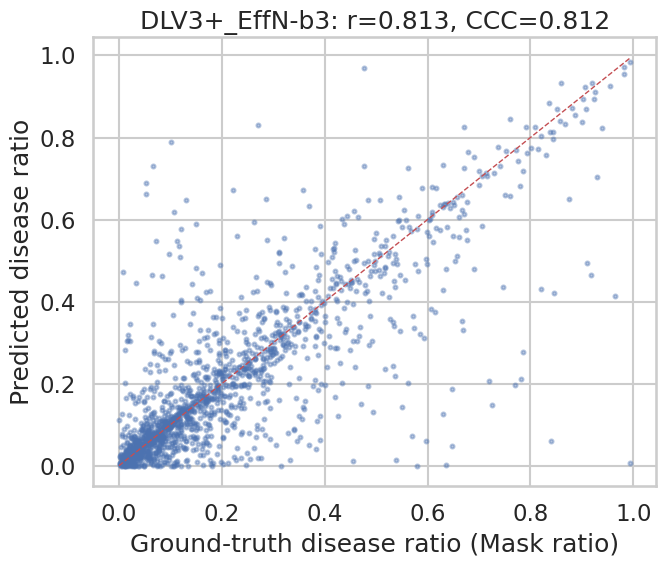

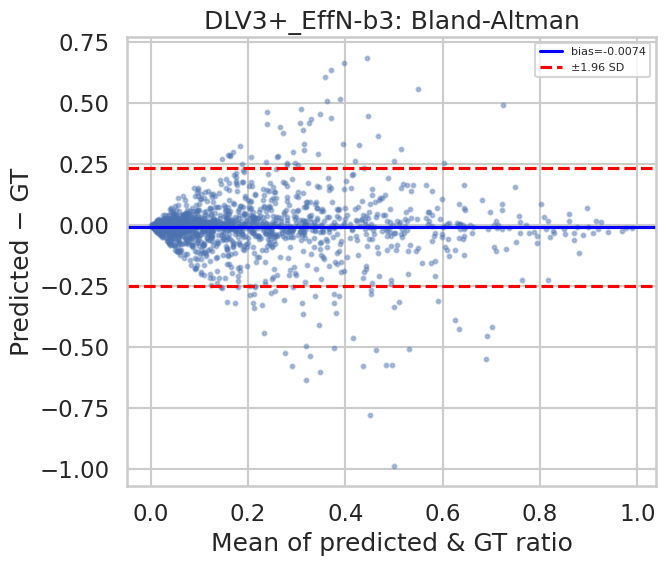

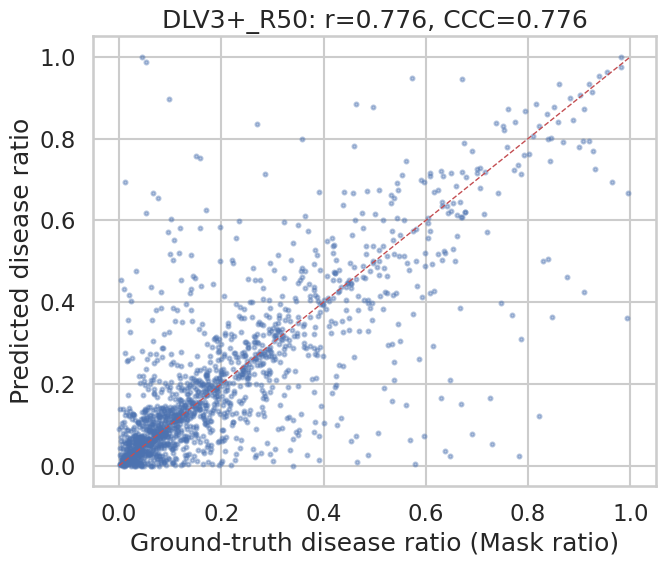

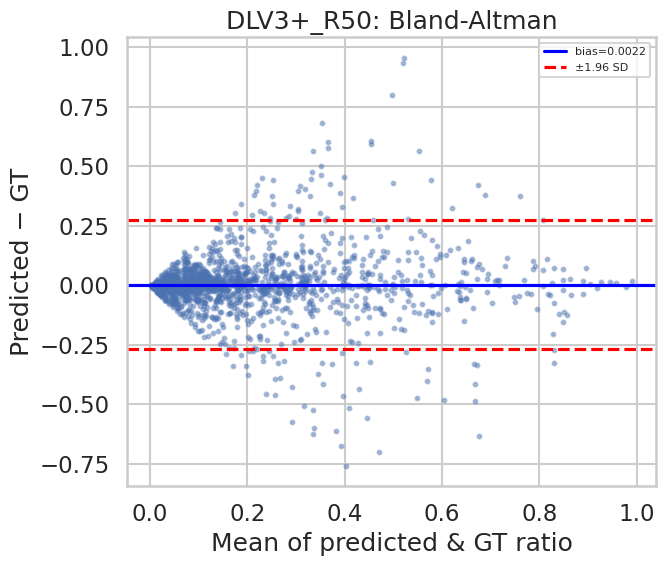

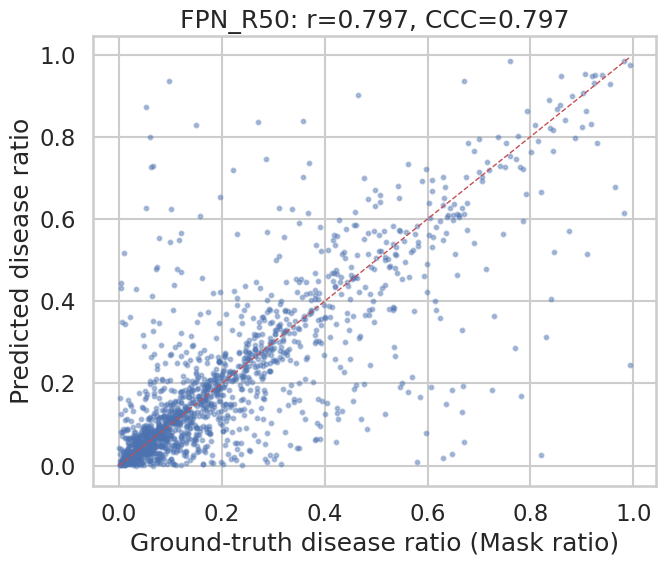

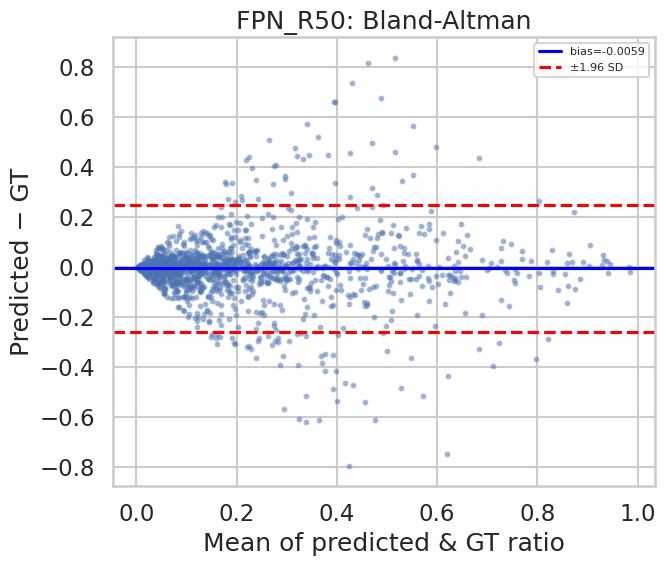

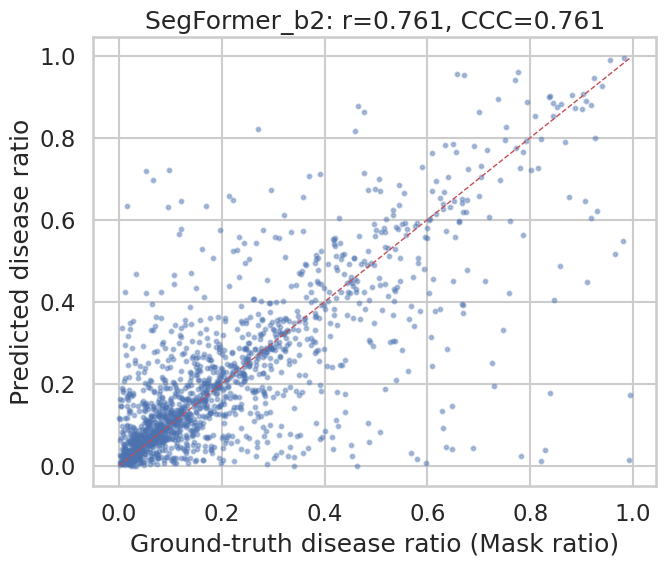

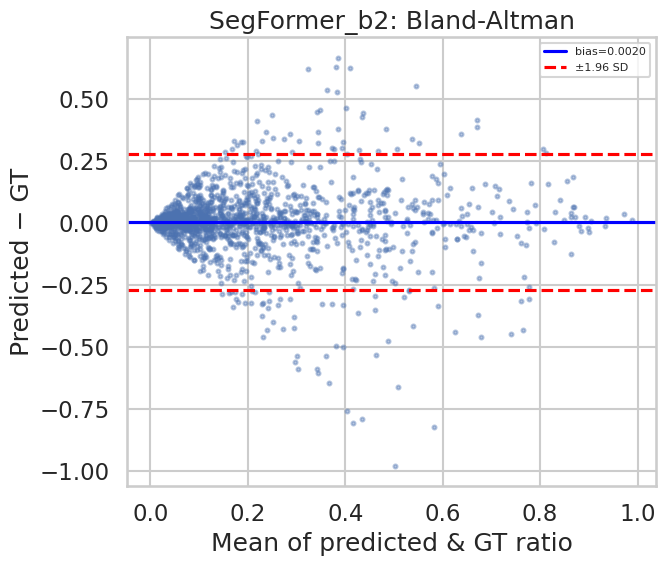

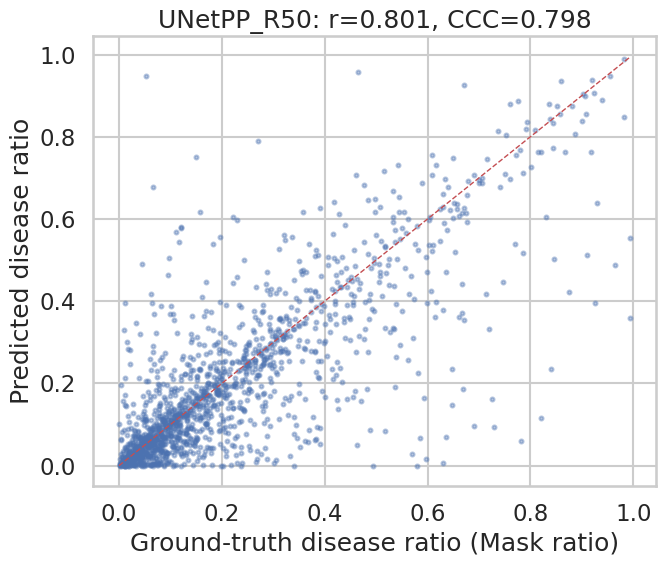

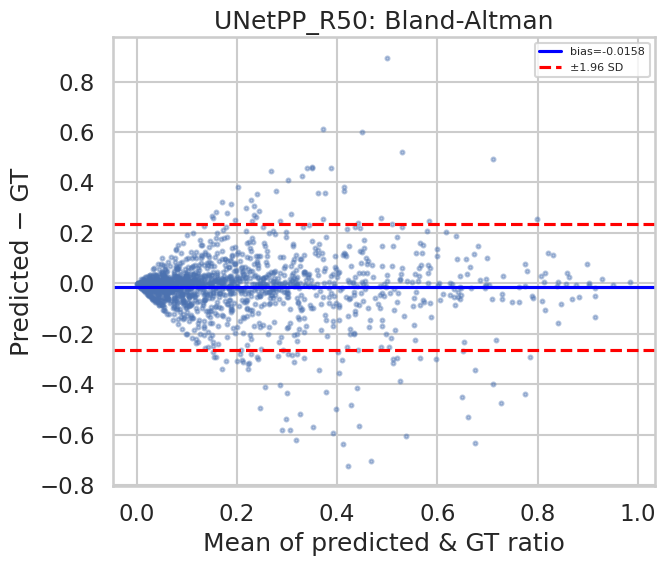

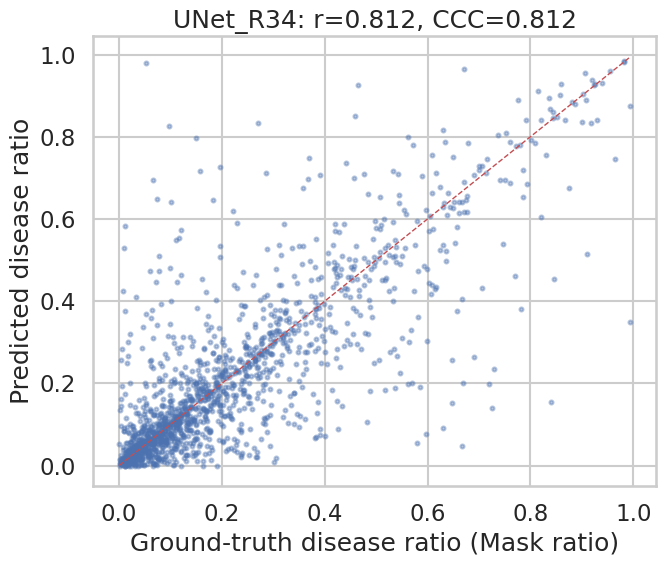

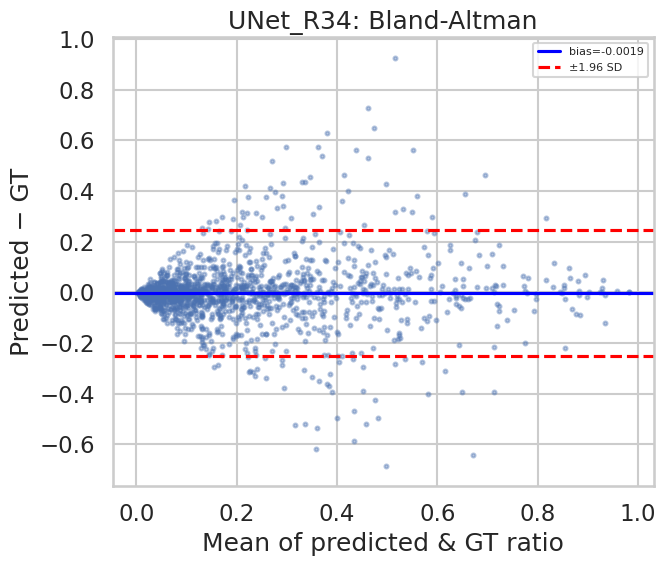

                        model    n  pearson_r     pearson_p  spearman_r    spearman_p      ccc      mae     rmse  weighted_kappa  bland_altman_bias  bland_altman_loa_lower  bland_altman_loa_upper
DeepLabV3Plus_efficientnet-b3 1561   0.812950  0.000000e+00    0.788313  0.000000e+00 0.812222 0.069092 0.124116        0.640736          -0.007438               -0.250268                0.235393
                UNet_resnet34 1561   0.812008  0.000000e+00    0.789508  0.000000e+00 0.811813 0.073219 0.126783        0.643104          -0.001865               -0.250333                0.246603
              UNetPP_resnet50 1561   0.801179  0.000000e+00    0.773030 1.854443e-310 0.798342 0.075084 0.128142        0.614893          -0.015778               -0.265026                0.233470
                 FPN_resnet50 1561   0.797225  0.000000e+00    0.780542 2.001954e-320 0.796892 0.072968 0.130603        0.646822          -0.005890               -0.261612                0.249833
       DeepLabV3Plus

In [9]:
def concordance_correlation_coefficient(y_true,y_pred):
    y_true,y_pred=np.asarray(y_true),np.asarray(y_pred)
    mt,mp=y_true.mean(),y_pred.mean(); vt,vp=y_true.var(),y_pred.var()
    covar=np.mean((y_true-mt)*(y_pred-mp))
    return (2*covar)/(vt+vp+(mt-mp)**2)

summary_rows=[]
for model_name,grp in per_image.groupby("model"):
    y_true,y_pred=grp["r_gt"].values,grp["r_pred"].values
    pearson_r,pearson_p=stats.pearsonr(y_true,y_pred)
    spearman_r,spearman_p=stats.spearmanr(y_true,y_pred)
    ccc=concordance_correlation_coefficient(y_true,y_pred)
    mae=mean_absolute_error(y_true,y_pred); rmse=mean_squared_error(y_true,y_pred)**0.5
    kappa=cohen_kappa_score(grp["grade_gt"],grp["grade_pred"],weights="linear")
    bias=(y_pred-y_true).mean(); loa_u=bias+1.96*(y_pred-y_true).std(); loa_l=bias-1.96*(y_pred-y_true).std()
    summary_rows.append({"model":model_name,"n":len(grp),"pearson_r":pearson_r,"pearson_p":pearson_p,
                          "spearman_r":spearman_r,"spearman_p":spearman_p,"ccc":ccc,"mae":mae,"rmse":rmse,
                          "weighted_kappa":kappa,"bland_altman_bias":bias,
                          "bland_altman_loa_lower":loa_l,"bland_altman_loa_upper":loa_u})

    short_name = model_name.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
    plt.figure(figsize=(7,6)); plt.scatter(y_true,y_pred,s=8,alpha=0.4)
    lims=[0,max(y_true.max(),y_pred.max())]; plt.plot(lims,lims,"r--",linewidth=1)
    plt.xlabel("Ground-truth disease ratio (Mask ratio)"); plt.ylabel("Predicted disease ratio")
    plt.title(f"{short_name}: r={pearson_r:.3f}, CCC={ccc:.3f}"); plt.tight_layout()
    plt.savefig(f"severity_scatter_{model_name}.png",dpi=150,bbox_inches="tight"); plt.show()

    mean_vals=(y_true+y_pred)/2; diff_vals=y_pred-y_true
    plt.figure(figsize=(7,6)); plt.scatter(mean_vals,diff_vals,s=8,alpha=0.4)
    plt.axhline(bias,color="blue",label=f"bias={bias:.4f}")
    plt.axhline(loa_u,color="red",linestyle="--",label="±1.96 SD"); plt.axhline(loa_l,color="red",linestyle="--")
    plt.xlabel("Mean of predicted & GT ratio"); plt.ylabel("Predicted − GT")
    plt.title(f"{short_name}: Bland-Altman"); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"severity_bland_altman_{model_name}.png",dpi=150,bbox_inches="tight"); plt.show()

summary=pd.DataFrame(summary_rows).sort_values("ccc",ascending=False)
summary.to_csv("severity_validation_summary.csv",index=False)
print(summary.to_string(index=False))


**Cross-link to Stage 4 narrative** — does segmentation quality (fg-IoU, computed fresh for all 6 models above) correlate with severity-estimation reliability (CCC)?

In [10]:
fg_iou_by_model=pd.Series({m:r["test_scores"]["fg_IoU"] for m,r in results.items()},name="fg_IoU")
merged=summary.set_index("model").join(fg_iou_by_model,how="inner")
corr=merged["fg_IoU"].corr(merged["ccc"])
print(f"Correlation between Stage-2 fg-IoU and Stage-3 severity CCC across {len(merged)} models: r = {corr:.3f}")
merged.to_csv("severity_vs_segmentation_quality.csv")
print(merged[["fg_IoU","ccc","pearson_r","weighted_kappa"]].round(4))


Correlation between Stage-2 fg-IoU and Stage-3 severity CCC across 6 models: r = 0.889
                               fg_IoU     ccc  pearson_r  weighted_kappa
DeepLabV3Plus_efficientnet-b3  0.6304  0.8122     0.8129          0.6407
UNet_resnet34                  0.6129  0.8118     0.8120          0.6431
UNetPP_resnet50                0.5954  0.7983     0.8012          0.6149
FPN_resnet50                   0.6135  0.7969     0.7972          0.6468
DeepLabV3Plus_resnet50         0.5904  0.7760     0.7761          0.6017
SegFormer_b2                   0.5792  0.7610     0.7613          0.5776


**Combined scatter panel (paper figure)** — all 6 models in one 2×3 grid so the
per-architecture predicted-vs-GT severity agreement can be compared side-by-side. Annotated
with Pearson r and CCC per subplot. The individual per-model files above are kept too.

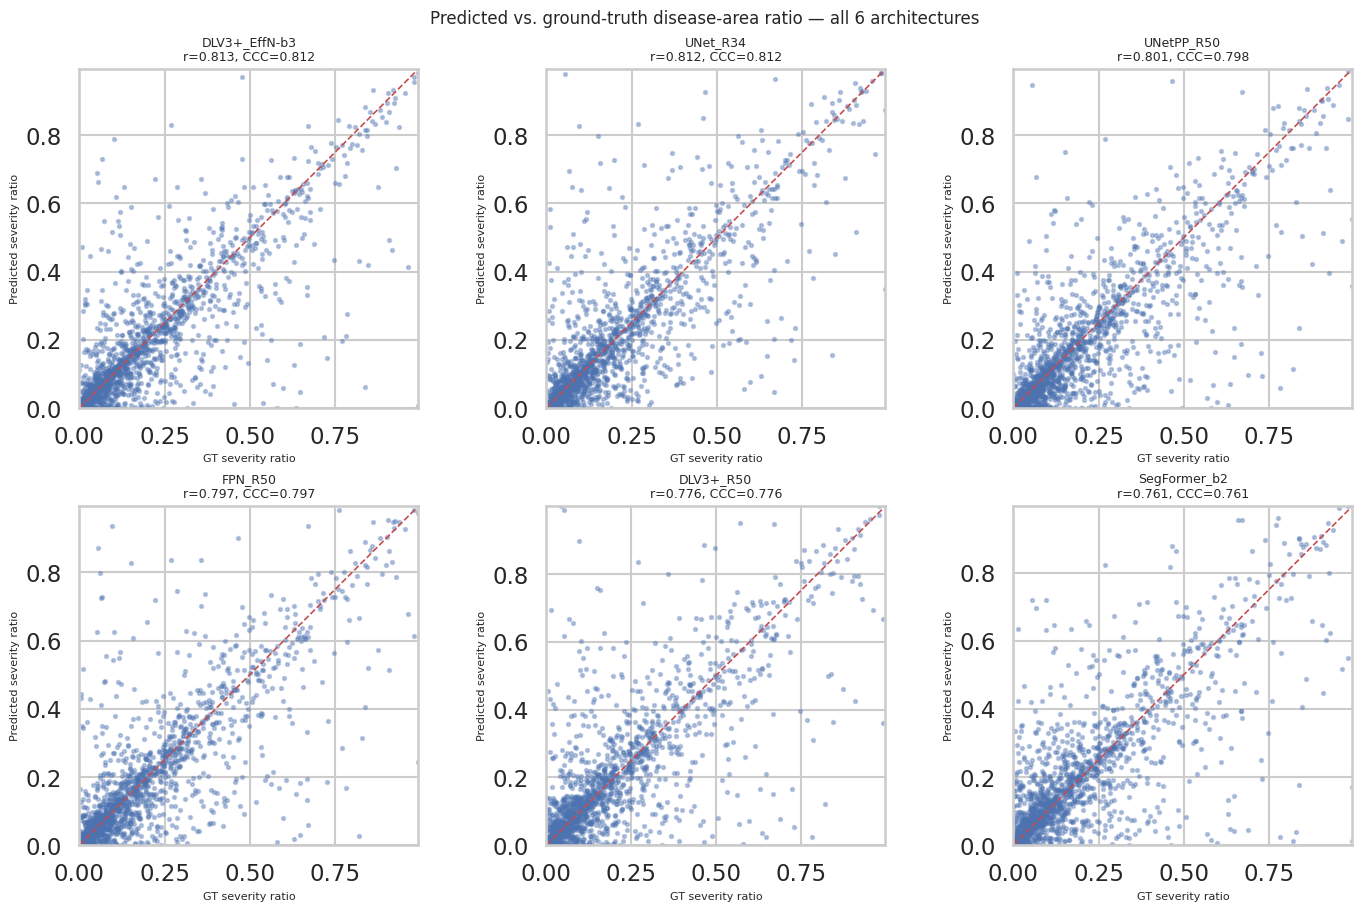

Saved severity_scatter_combined.png


In [11]:
MODEL_ORDER = ["DeepLabV3Plus_efficientnet-b3","UNet_resnet34","UNetPP_resnet50","FPN_resnet50","DeepLabV3Plus_resnet50","SegFormer_b2"]
MODEL_ORDER = [m for m in MODEL_ORDER if m in summary.set_index("model").index]

fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
axes = axes.ravel()
for ax_i, model_name in enumerate(MODEL_ORDER):
    ax = axes[ax_i]
    grp = per_image[per_image.model == model_name]
    y_true, y_pred = grp["r_gt"].values, grp["r_pred"].values
    row = summary[summary.model == model_name].iloc[0]
    ax.scatter(y_true, y_pred, s=6, alpha=0.35, rasterized=True)
    lim = [0, max(y_true.max(), y_pred.max())]
    ax.plot(lim, lim, "r--", lw=1.2)
    ax.set_xlim(lim); ax.set_ylim(lim)
    short = model_name.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
    ax.set_title(f"{short}\nr={row.pearson_r:.3f}, CCC={row.ccc:.3f}", fontsize=9)
    ax.set_xlabel("GT severity ratio", fontsize=8)
    ax.set_ylabel("Predicted severity ratio", fontsize=8)
    ax.set_aspect("equal")
# hide unused axes
for ax_i in range(len(MODEL_ORDER), len(axes)):
    axes[ax_i].set_visible(False)
fig.suptitle("Predicted vs. ground-truth disease-area ratio — all 6 architectures", fontsize=12)
plt.savefig("severity_scatter_combined.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved severity_scatter_combined.png")


**Combined Bland-Altman panel (paper figure)** — all 6 models in one 2×3 grid
showing systematic bias and limits of agreement. Reviewers use this to assess whether
any architecture has a *directional* bias (e.g., consistently over- or under-estimating
severity), not just lower correlation.

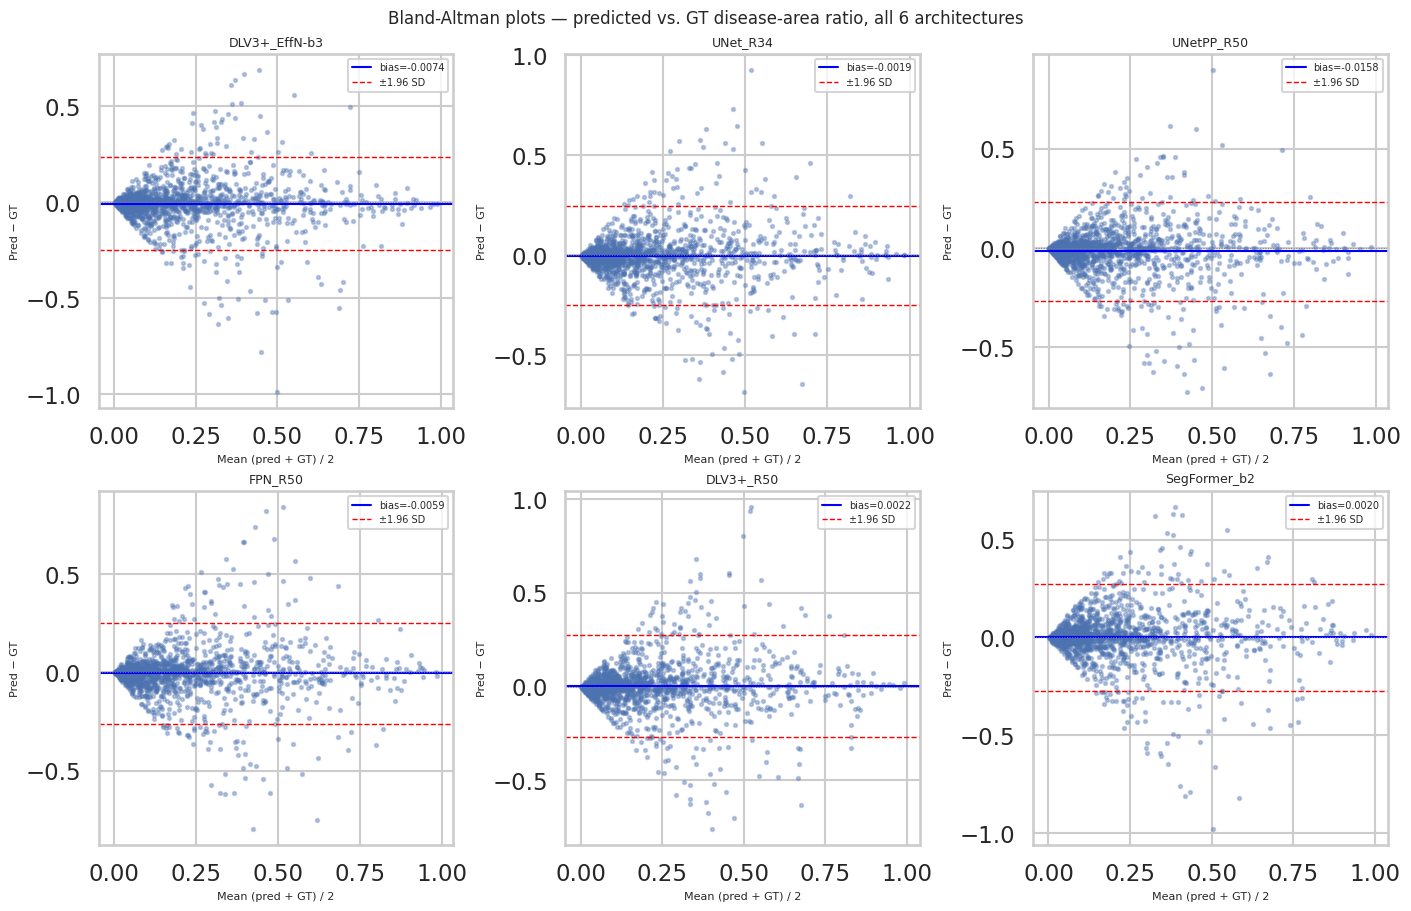

Saved severity_bland_altman_combined.png


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
axes = axes.ravel()
for ax_i, model_name in enumerate(MODEL_ORDER):
    ax = axes[ax_i]
    grp = per_image[per_image.model == model_name]
    y_true, y_pred = grp["r_gt"].values, grp["r_pred"].values
    row = summary[summary.model == model_name].iloc[0]
    mean_v = (y_true + y_pred) / 2
    diff_v = y_pred - y_true
    ax.scatter(mean_v, diff_v, s=6, alpha=0.35, rasterized=True)
    ax.axhline(row.bland_altman_bias, color="blue", lw=1.5, label=f"bias={row.bland_altman_bias:.4f}")
    ax.axhline(row.bland_altman_loa_upper, color="red", lw=1, ls="--", label="±1.96 SD")
    ax.axhline(row.bland_altman_loa_lower, color="red", lw=1, ls="--")
    ax.axhline(0, color="gray", lw=0.7, ls=":")
    short = model_name.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
    ax.set_title(f"{short}", fontsize=9)
    ax.set_xlabel("Mean (pred + GT) / 2", fontsize=8)
    ax.set_ylabel("Pred − GT", fontsize=8)
    ax.legend(fontsize=7)
for ax_i in range(len(MODEL_ORDER), len(axes)):
    axes[ax_i].set_visible(False)
fig.suptitle("Bland-Altman plots — predicted vs. GT disease-area ratio, all 6 architectures", fontsize=12)
plt.savefig("severity_bland_altman_combined.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved severity_bland_altman_combined.png")


**Cross-link scatter plot (paper figure)** — fg-IoU (Stage 2 segmentation quality)
vs. severity CCC (Stage 3 agreement) across all 6 architectures with a regression line.
This is the visual evidence for the r = 0.885 result that links segmentation accuracy to
severity-estimation reliability and directly motivates Stage 4 (XAI faithfulness).

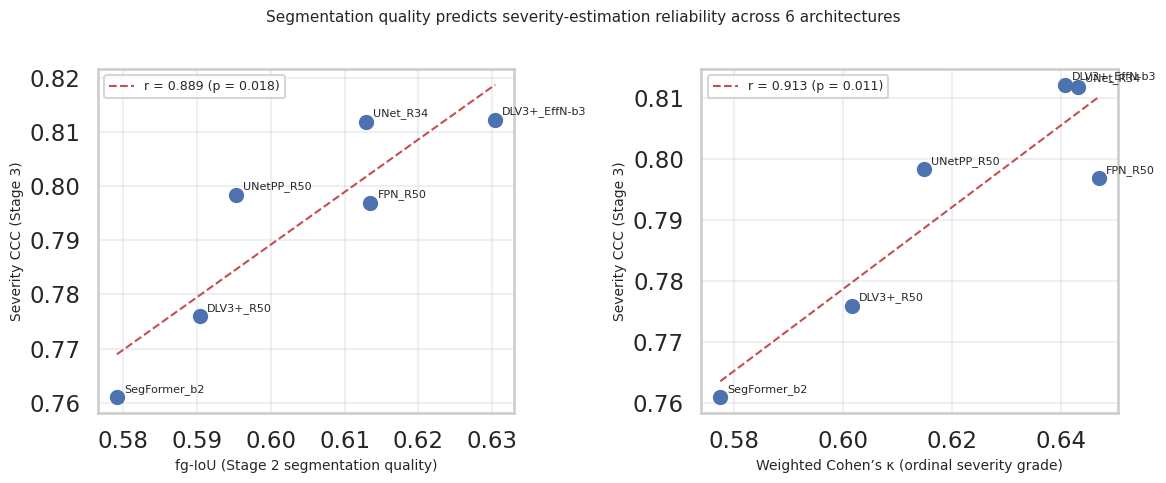

Saved severity_vs_segmentation_crosslink.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (xcol, xlabel) in zip(axes, [
    ("fg_IoU", "fg-IoU (Stage 2 segmentation quality)"),
    ("weighted_kappa", "Weighted Cohen\u2019s \u03ba (ordinal severity grade)"),
]):
    xs = merged[xcol].values; ys = merged["ccc"].values
    ax.scatter(xs, ys, s=90, zorder=3)
    for _, r in merged.iterrows():
        short = r.name.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
        ax.annotate(short, (r[xcol], r["ccc"]), textcoords="offset points", xytext=(5,4), fontsize=8)
    from scipy.stats import linregress
    m, b, r_val, p_val, _ = linregress(xs, ys)
    xr = np.linspace(xs.min(), xs.max(), 50)
    ax.plot(xr, m*xr+b, "r--", lw=1.5, label=f"r = {r_val:.3f} (p = {p_val:.3f})")
    ax.set_xlabel(xlabel, fontsize=10); ax.set_ylabel("Severity CCC (Stage 3)", fontsize=10)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

fig.suptitle("Segmentation quality predicts severity-estimation reliability across 6 architectures",
             fontsize=11)
plt.tight_layout()
plt.savefig("severity_vs_segmentation_crosslink.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved severity_vs_segmentation_crosslink.png")


In [14]:
# ── Save & verify all Stage 3 outputs ──────────────────────────────────────
import zipfile, os
from pathlib import Path

OUT = Path("/kaggle/working")

expected = {
    # ── CSVs ──
    "severity_validation_per_image.csv":     "Per-image predictions for all 6 models",
    "severity_validation_summary.csv":       "Per-model Pearson/CCC/MAE/kappa/Bland-Altman",
    "severity_vs_segmentation_quality.csv":  "Cross-link: fg-IoU vs severity CCC",
    # ── Combined paper figures ──
    "severity_scatter_combined.png":         "2×3 scatter panel (paper figure)",
    "severity_bland_altman_combined.png":    "2×3 Bland-Altman panel (paper figure)",
    "severity_vs_segmentation_crosslink.png":"Cross-link scatter (paper figure)",
}
# Per-model individual figures
for m in results.keys():
    expected[f"severity_scatter_{m}.png"]      = f"Scatter — {m}"
    expected[f"severity_bland_altman_{m}.png"] = f"Bland-Altman — {m}"

print(f"{'File':<52} {'Size':>9}  Status")
print("─" * 70)
missing = []
for fname, desc in expected.items():
    p = OUT / fname
    if p.exists():
        size = f"{p.stat().st_size/1024:.1f} KB"
        print(f"{fname:<52} {size:>9}  ✓")
    else:
        print(f"{fname:<52} {'':>9}  ✗ MISSING")
        missing.append(fname)

print(f"\n{len(expected)-len(missing)}/{len(expected)} files present.")

# Zip everything
zip_path = OUT / "plantseg_stage3_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in expected:
        p = OUT / fname
        if p.exists():
            zf.write(p, fname)

print(f"\nArchive saved: {zip_path.name}  ({zip_path.stat().st_size/1024/1024:.2f} MB)")
print("Download from Kaggle Output tab → plantseg_stage3_results.zip")

File                                                      Size  Status
──────────────────────────────────────────────────────────────────────
severity_validation_per_image.csv                    1417.6 KB  ✓
severity_validation_summary.csv                         1.4 KB  ✓
severity_vs_segmentation_quality.csv                    1.6 KB  ✓
severity_scatter_combined.png                         517.3 KB  ✓
severity_bland_altman_combined.png                    472.6 KB  ✓
severity_vs_segmentation_crosslink.png                128.5 KB  ✓
severity_scatter_DeepLabV3Plus_efficientnet-b3.png    146.5 KB  ✓
severity_bland_altman_DeepLabV3Plus_efficientnet-b3.png  127.2 KB  ✓
severity_scatter_UNet_resnet34.png                    148.4 KB  ✓
severity_bland_altman_UNet_resnet34.png               126.3 KB  ✓
severity_scatter_UNetPP_resnet50.png                  146.9 KB  ✓
severity_bland_altman_UNetPP_resnet50.png             127.8 KB  ✓
severity_scatter_DeepLabV3Plus_resnet50.png           148.7 KB 

---
## End of Pipeline

Outputs in the working directory:
- `s2_result_DeepLabV3Plus_efficientnet-b3.pkl`, `s2_result_UNet_resnet34.pkl` — backup artifacts for the newly-trained models
- `severity_validation_per_image.csv`
- `severity_scatter_combined.png` — **2×3 combined scatter panel** (all 6 models, paper-ready)
- `severity_bland_altman_combined.png` — **2×3 combined Bland-Altman panel** (paper-ready)
- `severity_vs_segmentation_crosslink.png` — **cross-link scatter** (fg-IoU & κ vs. severity CCC, paper-ready) — every test image × all 6 models: `r_pred`, `r_gt`, `abs_err`, severity grades
- `severity_validation_summary.csv` — per-model Pearson/Spearman/CCC/MAE/RMSE/weighted-kappa/Bland-Altman (**the key table for the paper**)
- `severity_scatter_<model>.png`, `severity_bland_altman_<model>.png` — one pair per model
- `severity_vs_segmentation_quality.csv` — fg-IoU vs. severity-CCC cross-link (Stage 4 narrative support)
